# 02 — Test de residus_par_groupe sur données synthétiques
Objectif : vérifier que la fonction du cœur retrouve des biais **connus**. On fabrique cinq groupes de 200 observations autour d'une prédiction constante, avec un biais vrai différent par groupe, puis on compare le biais estimé au biais vrai.

Convention : **résidu = observé − prédit**. Un biais positif signifie que l'observé dépasse la prédiction ; en crédit, pour une PD, le modèle sous-estime alors le risque.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().parent
sys.path.append(str(RACINE / "src"))
from validation_toolkit.core.residuals import residus_par_groupe

## 1. Données synthétiques
Bruit gaussien d'écart-type 1 ; biais vrais : 0, 0, +0,5, −0,5, +1.

In [2]:
rng = np.random.default_rng(0)
groupes = ["G1", "G2", "G3", "G4", "G5"]
N_PAR_GROUPE = 200
biais_vrai = pd.Series([0.0, 0.0, 0.5, -0.5, 1.0], index=groupes, name="biais_vrai")

df = pd.DataFrame({"groupe": np.repeat(groupes, N_PAR_GROUPE)})
df["predit"] = 2.0
df["observe"] = df["predit"] + df["groupe"].map(biais_vrai) + rng.normal(0, 1, len(df))

## 2. Biais estimé contre biais vrai
`ecart_en_erreurs_standard` = (biais estimé − biais vrai) / erreur standard du biais (σ / √n). Une valeur dans [−2 ; 2] signifie que l'écart est du bruit d'échantillonnage.

In [3]:
r = residus_par_groupe(df, "groupe", "observe", "predit")

sigma = (df["observe"] - df["predit"]).groupby(df["groupe"]).std()
comparaison = r.join(biais_vrai)
comparaison["erreur_standard"] = sigma / np.sqrt(comparaison["n"])
comparaison["ecart_en_erreurs_standard"] = (comparaison["biais_moyen"] - comparaison["biais_vrai"]) / comparaison["erreur_standard"]
display(comparaison.round(2))

assert comparaison["ecart_en_erreurs_standard"].abs().max() < 3, "un biais estimé s'écarte trop du biais vrai"

,n,biais_moyen,rmse,part_positifs,biais_vrai,erreur_standard,ecart_en_erreurs_standard
groupe,,,,,,,
G1,200,0.02,0.96,0.51,0.0,0.07,0.22
G2,200,-0.09,1.03,0.44,0.0,0.07,-1.22
G3,200,0.51,1.12,0.71,0.5,0.07,0.07
G4,200,-0.54,1.14,0.31,-0.5,0.07,-0.51
G5,200,0.86,1.23,0.86,1.0,0.06,-2.19


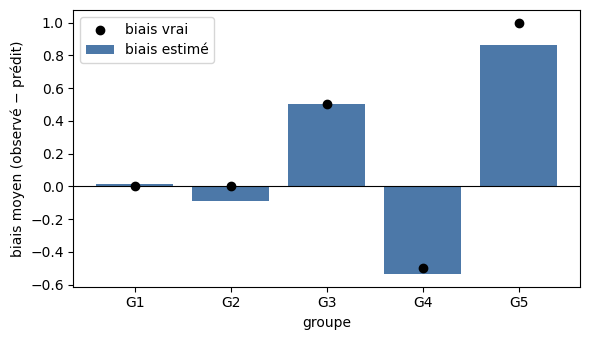

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(r.index, r["biais_moyen"], color="#4C78A8", label="biais estimé")
ax.scatter(biais_vrai.index, biais_vrai.values, color="k", zorder=3, label="biais vrai")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("groupe"); ax.set_ylabel("biais moyen (observé − prédit)")
ax.legend(); plt.tight_layout(); plt.show()

## Lecture
- Quatre groupes sur cinq ont un biais estimé à moins de 2 erreurs standard du biais vrai ; G5 est à −2,2. Avec cinq groupes, un écart un peu au-delà de 2 arrive par hasard environ une fois sur cinq ; l'assertion de la cellule vérifie donc le seuil de 3.
- G3 (+0,5) et G4 (−0,5) ont un RMSE presque identique (≈ 1,1) mais des biais **opposés** : le RMSE seul ne distingue pas un modèle trop optimiste d'un modèle trop prudent, d'où le biais signé et la part de résidus positifs.
- Sans biais (G1, G2), la part de résidus positifs est proche de 50 %.